In [1]:
%load_ext autoreload
%autoreload 2
    
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

from generic_plotting_functions import *

In [2]:
def format_exp_df(df):
    df.columns = ['lib_ID', 'lib_name', 'gene', 'FBgn_ID', 'category_ID', 'category_desc', 'rpkm', 'exp_bin_ID']
    stage_order = [
        "embryo 00-02hr", "embryo 02-04hr", "embryo 04-06hr", "embryo 06-08hr", "embryo 08-10hr", "embryo 10-12hr", "embryo 12-14hr", 
        "embryo 14-16hr", "embryo 16-18hr", "embryo 18-20hr", "embryo 20-22hr", "embryo 22-24hr", "larva L1", "larva L2", "larva L3 12hr",
        "larva L3 puffstage 1-2","larva L3 puffstage 3-6","larva L3 puffstage 7-9","white prepupa","prepupa 12hr","pupa 1d","pupa 2d",
        "pupa 3d","pupa 4d","adult male 01day","adult male 05day","adult male 30day","adult female 01day","adult female 05day","adult female 30day",
    ]
    df['stage'] = stage_order
    df["stage"] = pd.Categorical(
        df["stage"],
        categories=stage_order,
        ordered=True
    )

    df = df.sort_values("stage")
    return df

def format_tissue_df(df):
    df.columns = ['lib_ID', 'lib_name', 'gene', 'FBgn_ID', 'category_ID', 'category_desc', 'rpkm', 'exp_bin_ID']
    tissue_order = [
        "imaginal disc, larvae L3 wandering",
        "central nervous system, larvae L3", "central nervous system, pupae P8",
        "head, virgin 1-day female", "head, virgin 4-day female", "head, virgin 20-day female",
        "head, mated 1-day female", "head, mated 4-day female", "head, mated 20-day female",
        "head, mated 1-day male", "head, mated 4-day male", "head, mated 20-day male",
        "salivary gland, larvae L3 wandering", "salivary gland, white prepupae",
        "digestive system, larvae L3 wandering", "digestive system, 1-day adult",
        "digestive system, 4-day adult", "digestive system, 20-day adult",
        "fat body, larvae L3 wandering", "fat body, white prepupae", "fat body, pupae P8",
        "carcass, larvae L3 wandering", "carcass, 1-day adult",
        "carcass, 4-day adult", "carcass, 20-day adult",
        "ovary, virgin 4-day female", "ovary, mated 4-day female",
        "testis, mated 4-day male", "accessory gland, mated 4-day male"
    ]
    df['tissue'] = tissue_order
    df["tissue"] = pd.Categorical(
        df["tissue"],
        categories=tissue_order,
        ordered=True
    )

    df = df.sort_values("tissue")
    return df


def modencode_color(x):
    if x == 0:
        return "#9B59FF"  # no/extremely low
    elif x <= 3:
        return "#64B5F6"  # very low
    elif x <= 10:
        return "#2DE2C5"  # low
    elif x <= 25:
        return "#7BED8D"  # moderate
    elif x <= 50:
        return "#B5F23D"  # moderately high
    elif x <= 100:
        return "#F2DD00"  # high
    elif x <= 1000:
        return "#FF8C00"  # very high
    else:
        return "#FF4500"  # extremely high



In [3]:
CG17385_dev_exp_df = format_exp_df(pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/rna_seq/flybase/modENCODE_mRNA-Seq_development_CG17385.tsv', sep='\t'))
CG17385_tissue_exp_df = format_tissue_df(pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/rna_seq/flybase/modENCODE_mRNA-Seq_tissues_CG17385.tsv', sep='\t'))

Trem_dev_exp_df = format_exp_df(pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/rna_seq/flybase/modENCODE_mRNA-Seq_development_Trem.tsv', sep='\t'))
Trem_tissue_exp_df = format_tissue_df(pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/rna_seq/flybase/modENCODE_mRNA-Seq_tissues_Trem.tsv', sep='\t'))

CG4854_dev_exp_df = format_exp_df(pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/rna_seq/flybase/modENCODE_mRNA-Seq_development_CG4854.tsv', sep='\t'))
CG4854_tissue_exp_df = format_tissue_df(pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/rna_seq/flybase/modENCODE_mRNA-Seq_tissues_CG4854.tsv', sep='\t'))



/tmp/ipykernel_833552/1960393530.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_833552/1960393530.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_833552/1960393530.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_833552/1960393530.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_833552/1960393530.py:15: FutureWa

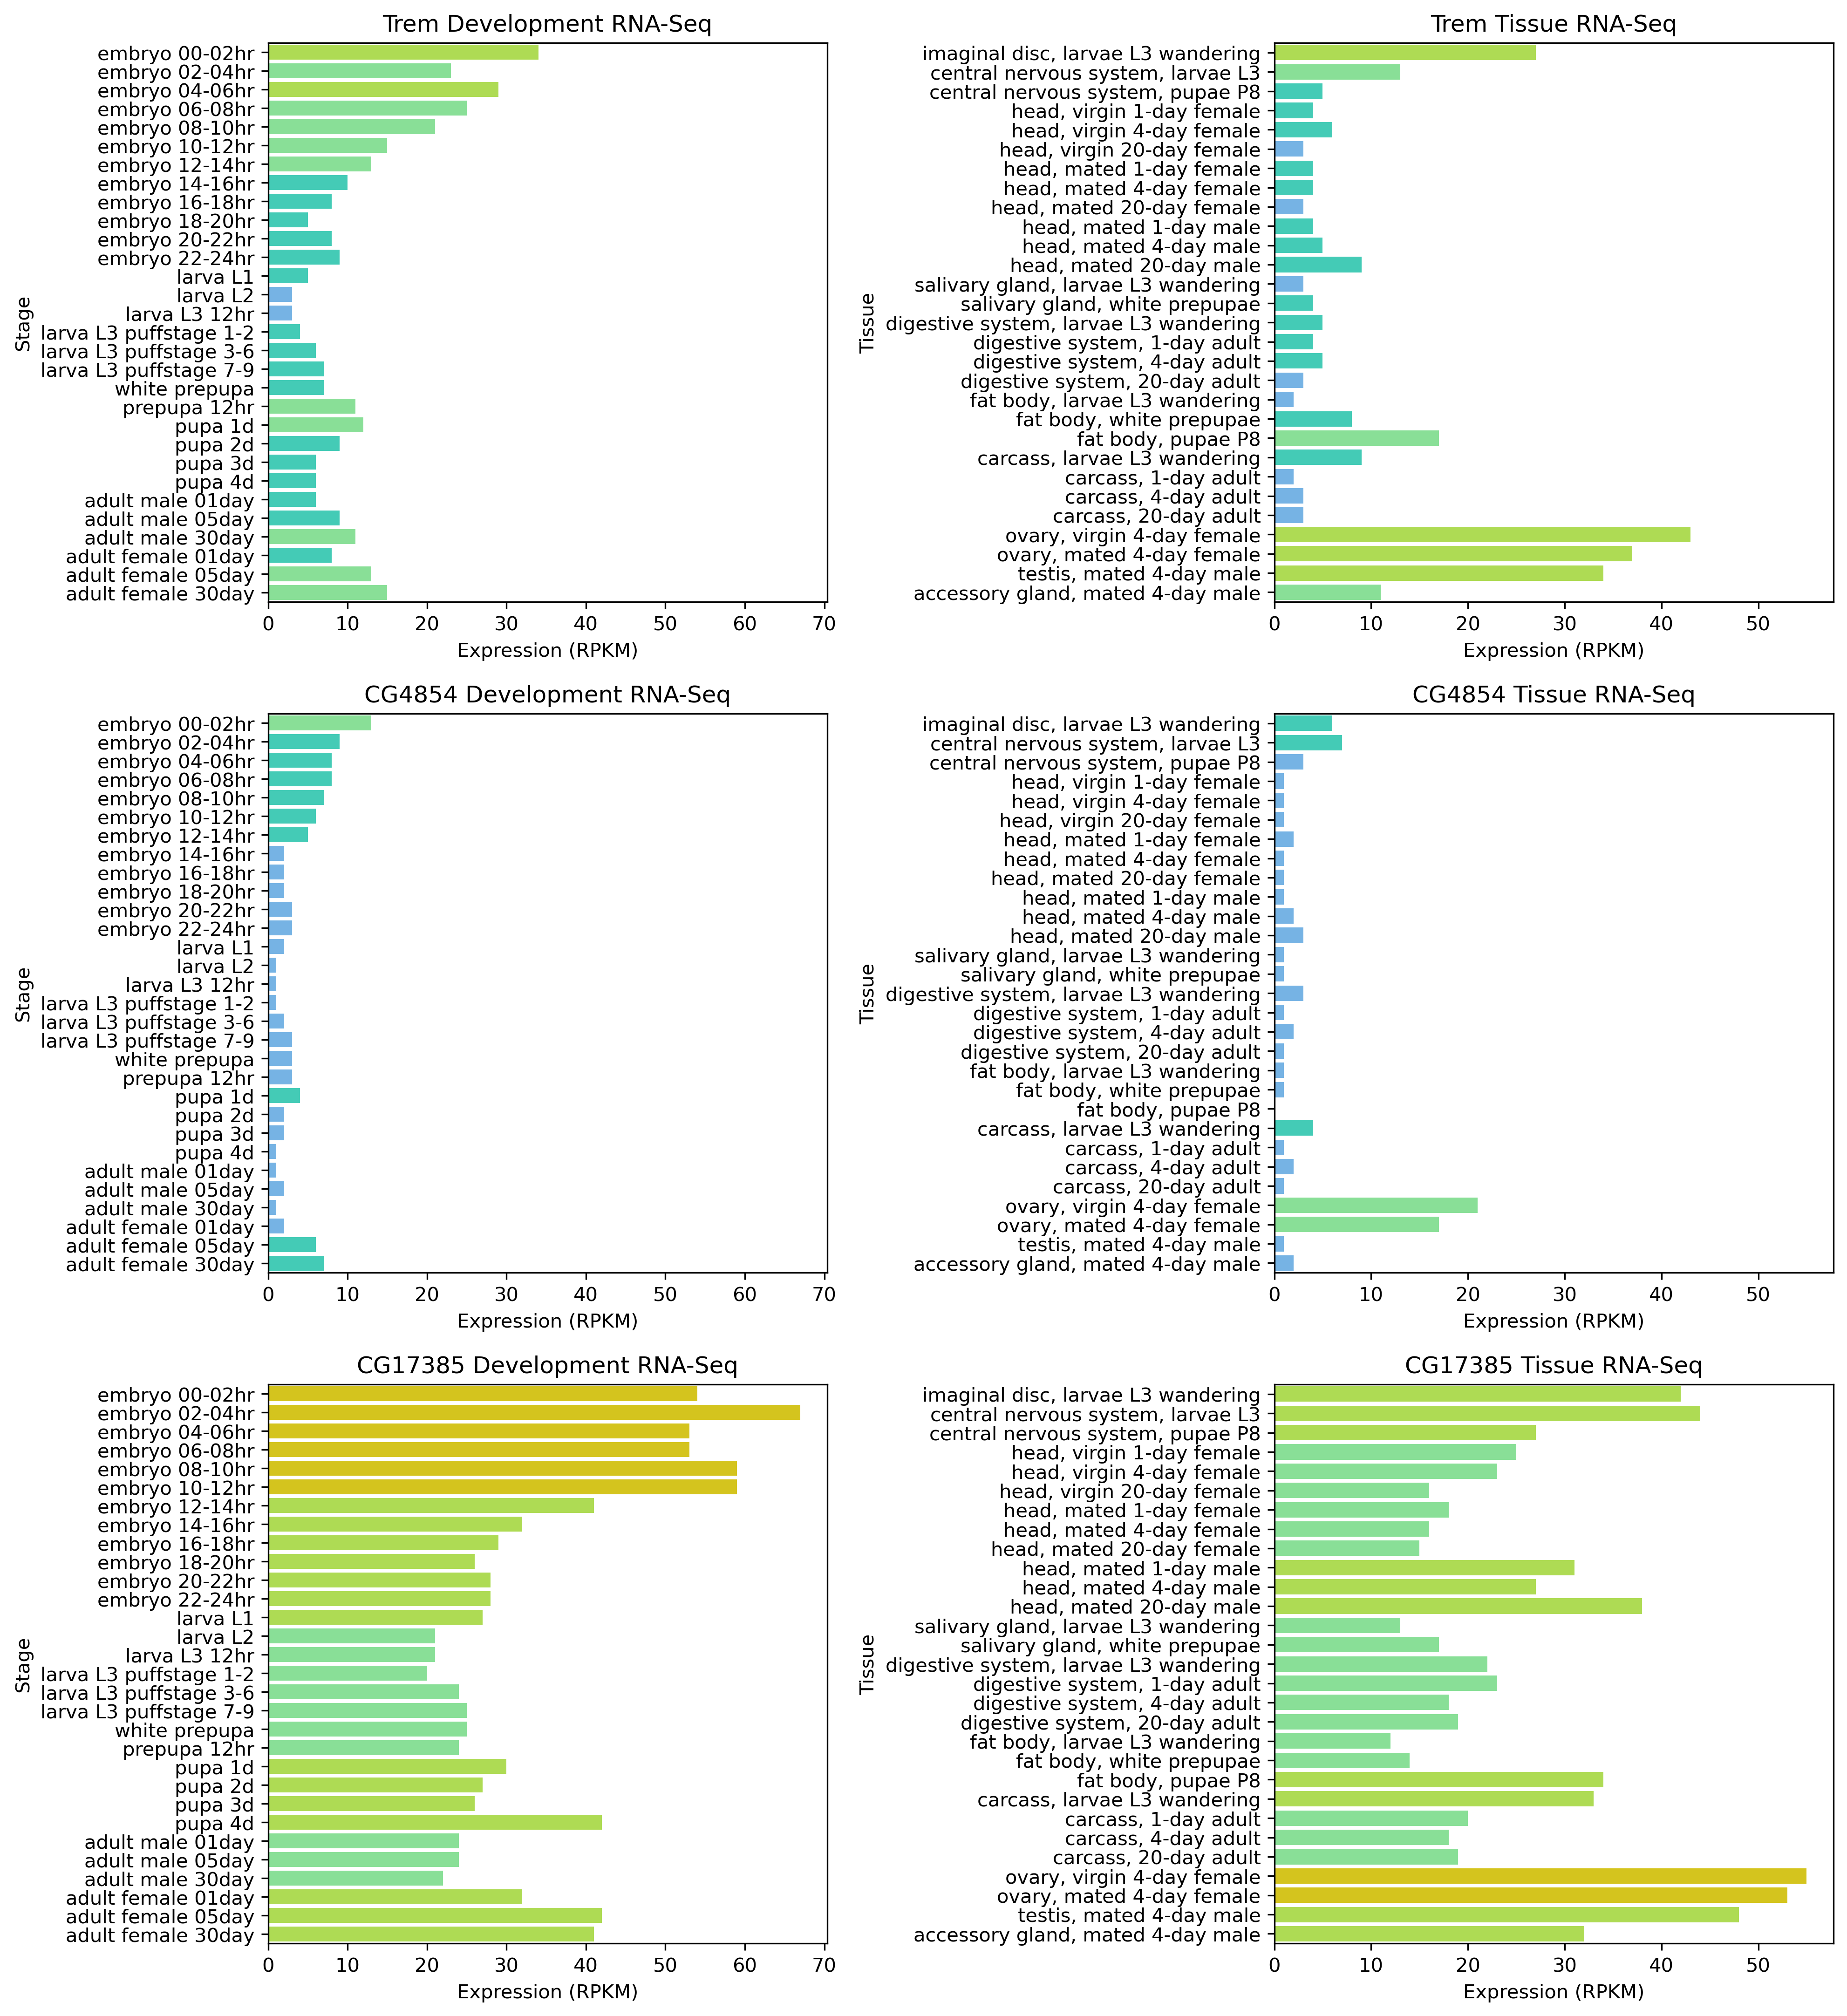

In [4]:
import matplotlib.pyplot as plt

fig, axs = init_subplots_exact(6,3,dpi=300, y_ratios=[1]*3, x_ratios=[1]*2, xspace=1.8, sharex=True)

zipped = [
    (Trem_dev_exp_df, Trem_tissue_exp_df, 'Trem'),
    (CG4854_dev_exp_df, CG4854_tissue_exp_df, 'CG4854'),
    (CG17385_dev_exp_df, CG17385_tissue_exp_df, 'CG17385'),
]

for i, (dev_df, tissue_df, factor) in enumerate(zipped):

    ax=axs[2*i]
    colors = dev_df['rpkm'].apply(modencode_color).tolist()
    sns.barplot(
        data=dev_df,
        x="rpkm",
        y="stage",
        order=dev_df['stage'].tolist(),
        orient="h",
        palette=colors,
        ax=ax
    )
    
    ax.set_xlabel("Expression (RPKM)")
    ax.set_ylabel("Stage")
    ax.set_title(f"{factor} Development RNA-Seq")
    
    ax=axs[2*i+1]
    colors = tissue_df['rpkm'].apply(modencode_color).tolist()
    sns.barplot(
        data=tissue_df,
        x="rpkm",
        y="tissue",
        order=tissue_df['tissue'].tolist(),
        orient="h",
        palette=colors,
        ax=ax
    )
    
    ax.set_xlabel("Expression (RPKM)")
    ax.set_ylabel("Tissue")
    ax.set_title(f"{factor} Tissue RNA-Seq")
        
plt.show()

# Legend

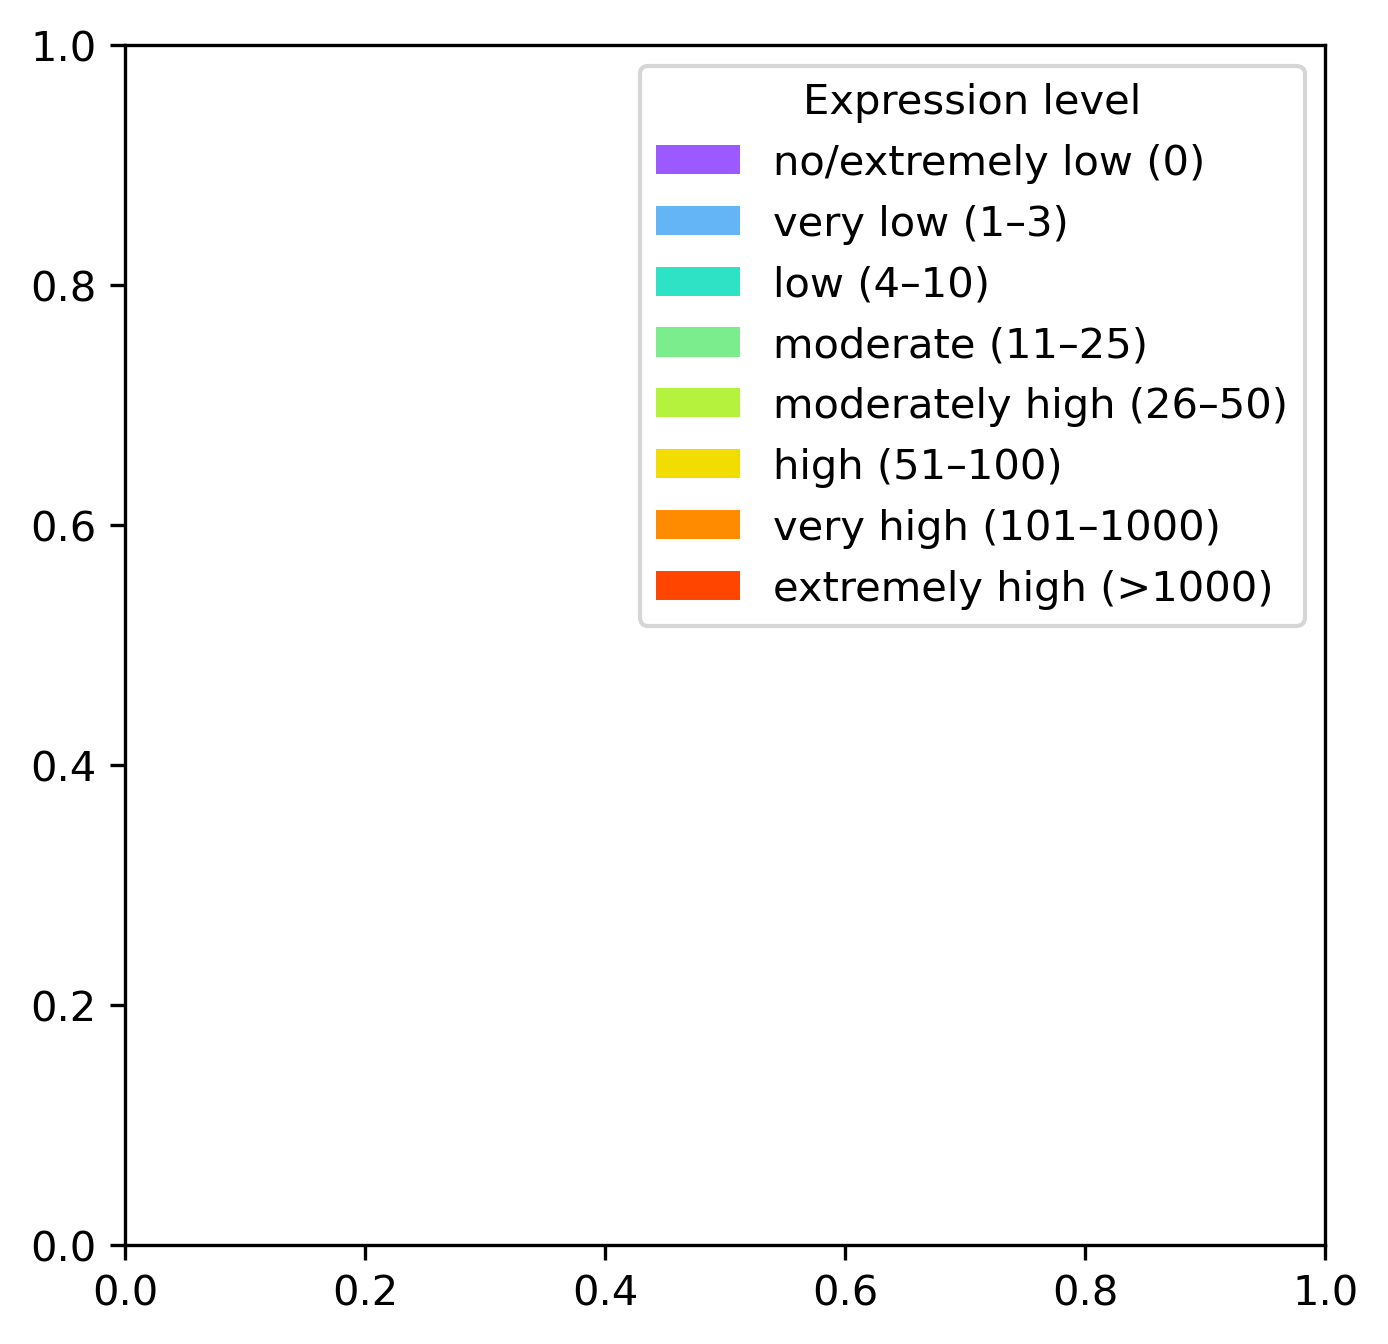

In [5]:
from matplotlib.patches import Patch

def modencode_legend():
    return [
        Patch(facecolor="#9B59FF", label="no/extremely low (0)"),
        Patch(facecolor="#64B5F6", label="very low (1–3)"),
        Patch(facecolor="#2DE2C5", label="low (4–10)"),
        Patch(facecolor="#7BED8D", label="moderate (11–25)"),
        Patch(facecolor="#B5F23D", label="moderately high (26–50)"),
        Patch(facecolor="#F2DD00", label="high (51–100)"),
        Patch(facecolor="#FF8C00", label="very high (101–1000)"),
        Patch(facecolor="#FF4500", label="extremely high (>1000)")
    ]

fig, ax = init_subplots_exact(1,1, dpi=300)
ax.legend(handles=modencode_legend(), title="Expression level")